# Group Assignment (Demo 3)
This notebook contains introductory Natural Language Processing content for the Group Assignment, linked to Big Data session 4: NLP.

In what follows, we will:
1. Extract & engineer new features on the textual news dataset using sentiment analysis.
2. Use Large Language Models (LLMs) to create text embeddings and sentiment scores as features.
3. Combine the new textual features with the price history.
4. Train and evaluate predictive models.

# Initialize Spark Environment

### 1. Initialize PySpark & import packages

In [3]:
#spark.stop()

In [4]:
# import findspark
import findspark
# initialize findspark with spark directory
findspark.init("/Users/vincenzovantornout/Spark/spark-4.0.1-bin-hadoop3")
# import pyspark
import pyspark
# create spark contextp
sc = pyspark.SparkContext()
# create spark session
spark = pyspark.sql.SparkSession(sc)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
25/12/11 18:20:08 WARN Utils: Your hostname, MacBook-Pro-van-Vincenzo.local, resolves to a loopback address: 127.0.0.1; using 192.168.0.104 instead (on interface en0)
25/12/11 18:20:08 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/11 18:20:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [5]:
# import the required packages
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import pyspark.sql.functions as F
from pyspark.sql.types import ArrayType, DoubleType, NumericType, StringType
from pyspark.ml.feature import Word2Vec, StandardScaler, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml import Pipeline

from textblob import TextBlob

from string import punctuation
from nltk.corpus import stopwords

# 1. Preprocess Data
## 1.1 Import Scraped Data
Load the json file of Financial Times

In [ ]:
import pyspark.sql.functions as F
from pyspark.sql.types import DateType, StringType
import os

# --- FILE PATHS & LOADING ---
data_dir = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/Company_news_page_data"
json_names = [obs for obs in os.listdir(data_dir) if obs.lower().endswith(".json") or obs.lower().endswith(".jsonl")]
json_paths = [os.path.join(data_dir, obs) for obs in json_names]

# 1. LOAD RAW DATA
articles_df = spark.read.json(json_paths)

# --- DATE FIXING (FINAL, ROBUST FIX) ---
NEWS_RELEASE_FORMAT = "MMMM d, yyyy" 

# 2. FIX: Pre-check and clean the raw date string (CRITICAL FIX for empty/null)
articles_df = articles_df.withColumn(
    "date_clean_pre",
    F.when(
        (F.col("date").isNull()) | (F.trim(F.col("date")) == ""), 
        F.lit(None).cast(StringType())
    ).otherwise(
        F.col("date")
    )
)

# 3. FIX: Apply Multi-Format Parsing
articles_df = articles_df.withColumn(
    "date_final",
    F.when(
        F.col("date_clean_pre").rlike(r"^\d{4}-\d{2}-\d{2}T"),
        F.to_date(F.substring(F.col("date_clean_pre"), 1, 10), "yyyy-MM-dd")
    ).otherwise(
        F.to_date(F.col("date_clean_pre"), NEWS_RELEASE_FORMAT)
    )
)

# 4. Finalize Date Column
articles_df = articles_df.withColumn("date", F.col("date_final")) \
                         .drop("date_clean_pre", "date_final")
articles_df = articles_df.select("date", "title", "content", "url")

# --- MINIMAL FIX: REMOVE "Transcript:" PREFIX ---
# Simple regex replace that only affects rows starting with Transcript:
articles_df = articles_df.withColumn(
    "content",
    F.regexp_replace(F.col("content"), "^[Tt]ranscript:\\s*", "")
)

# --- MINIMAL FIX: REMOVE "Transcript:" PREFIX ---
# Simple regex replace that only affects rows starting with Transcript:
articles_df = articles_df.withColumn(
    "title",
    F.regexp_replace(F.col("title"), "^[Tt]ranscript:\\s*", "")
)


# That's it! Just one simple line added.

# Verification (This block should execute without any exceptions now)
articles_df.printSchema()
print(f"Total articles loaded (Date Check): {articles_df.count()}")

Number of JSON files found: 19

=== LOADING FILES INDIVIDUALLY ===
Loading file 1/19: ARG.TO_news.json
  Columns found: ['_corrupt_record']
  Row count: 194
  ⚠️  Only _corrupt_record column found
  After multiLine - Columns: ['content', 'date', 'title', 'url']
  ✓ Added to processing list
Loading file 2/19: FDY.TO_news.json
  Columns found: ['_corrupt_record']
  Row count: 230
  ⚠️  Only _corrupt_record column found
  After multiLine - Columns: ['content', 'date', 'title', 'url']
  ✓ Added to processing list
Loading file 3/19: CKG.V_news.json
  Columns found: ['_corrupt_record']
  Row count: 134
  ⚠️  Only _corrupt_record column found
  After multiLine - Columns: ['content', 'date', 'title', 'url']
  ✓ Added to processing list
Loading file 4/19: DMX.V_news.json
  Columns found: ['_corrupt_record']
  Row count: 320
  ⚠️  Only _corrupt_record column found
  After multiLine - Columns: ['content', 'date', 'title', 'url']
  ✓ Added to processing list
Loading file 5/19: EDG.V_news.json
  Co

25/12/11 18:35:50 ERROR Executor: Exception in task 0.0 in stage 165.0 (TID 205)
org.apache.spark.SparkDateTimeException: [CANNOT_PARSE_TIMESTAMP] Text '11.28.2024' could not be parsed at index 0. Use `try_to_timestamp` to tolerate invalid input string and return NULL instead. SQLSTATE: 22007
	at org.apache.spark.sql.errors.QueryExecutionErrors$.ansiDateTimeParseError(QueryExecutionErrors.scala:279)
	at org.apache.spark.sql.errors.QueryExecutionErrors.ansiDateTimeParseError(QueryExecutionErrors.scala)
	at org.apache.spark.sql.catalyst.expressions.GeneratedClass$GeneratedIteratorForCodegenStage1.processNext(Unknown Source)
	at org.apache.spark.sql.execution.BufferedRowIterator.hasNext(BufferedRowIterator.java:43)
	at org.apache.spark.sql.execution.WholeStageCodegenEvaluatorFactory$WholeStageCodegenPartitionEvaluator$$anon$1.hasNext(WholeStageCodegenEvaluatorFactory.scala:50)
	at org.apache.spark.sql.execution.SparkPlan.$anonfun$getByteArrayRdd$1(SparkPlan.scala:402)
	at org.apache.spark

DateTimeException: [CANNOT_PARSE_TIMESTAMP] Text '11.28.2024' could not be parsed at index 0. Use `try_to_timestamp` to tolerate invalid input string and return NULL instead. SQLSTATE: 22007

In [ ]:
articles_df.show(1000)

+----------+--------------------+--------------------+--------------------+
|      date|               title|             content|                 url|
+----------+--------------------+--------------------+--------------------+
|2025-10-23|Germany shelves c...|Value of precious...|https://www.ft.co...|
|2025-10-21|Silver’s history ...|Gold demand has s...|https://www.ft.co...|
|2025-10-14|Silver price hits...|Metal has staged ...|https://www.ft.co...|
|2025-06-30|Silver, the preci...|Its use in growin...|https://www.ft.co...|
|2025-11-06|US adds silver an...|Materials added m...|https://www.ft.co...|
|2025-10-17|Silverines cash i...|Come the end of t...|https://www.ft.co...|
|2025-11-14|Silver’s growth b...|Jewellers are bei...|https://www.ft.co...|
|2025-09-29|Singapore and Hon...|The industry is c...|https://www.ft.co...|
|2025-06-12|Silver and platin...|Prices climb more...|https://www.ft.co...|
|2025-11-11|Gold rally tempts...|Surging prices ar...|https://www.ft.co...|
|2025-11-14|

Full implemenation of punctuation and stopwords removal

In [ ]:
import pyspark.sql.functions as F
from pyspark.sql.types import StringType, ArrayType
from string import punctuation
from nltk.corpus import stopwords
import nltk
import re 

# --- NLTK SETUP & CONSTANTS ---
nltk.download('stopwords', quiet=True) 
PUNCTUATION_CHARS_UNESCAPED = "".join([char for char in punctuation if char not in ["!", "@", "#"]])
PUNCTUATION_REGEX = f"[{re.escape(PUNCTUATION_CHARS_UNESCAPED)}\n]" 

STOPWORDS = set(stopwords.words("english"))

# CRITICAL FINAL FIX: Convert stopwords to a SQL literal string, 
# ensuring any internal apostrophe (') is doubled up ('') to prevent ParseException.
STOPWORDS_LIST_ESCAPED = [word.replace("'", "''") for word in STOPWORDS]
STOPWORDS_SQL_LITERAL = ", ".join([f"'{word}'" for word in STOPWORDS_LIST_ESCAPED])


# --- UDF DEFINITION (Only Stopword UDF is necessary now) ---
def remove_stopwords_list(tokens):
    """Filters tokens; runs in Python worker."""
    if tokens is None: return None
    # Filter: 1) not a stopword, AND 2) not an empty string ('')
    return [word for word in tokens if word.lower() not in STOPWORDS and word != ''] 

remove_stopwords_udf = F.udf(remove_stopwords_list, ArrayType(StringType()))

print("UDFs and Constants defined successfully with final SQL escaping fix.")

UDFs and Constants defined successfully with final SQL escaping fix.


In [ ]:
articles_df.show(1000)
# --- CHECK HOW MANY ROWS START WITH "Transcript:" AFTER CLEANING ---
transcript_count_after = articles_df.filter(
    F.lower(F.col("content")).startswith("transcript:")
).count()

print(f"Rows starting with 'Transcript:' (case-insensitive) AFTER cleaning: {transcript_count_after}")


+----------+--------------------+--------------------+--------------------+
|      date|               title|             content|                 url|
+----------+--------------------+--------------------+--------------------+
|2025-10-23|Germany shelves c...|Value of precious...|https://www.ft.co...|
|2025-10-21|Silver’s history ...|Gold demand has s...|https://www.ft.co...|
|2025-10-14|Silver price hits...|Metal has staged ...|https://www.ft.co...|
|2025-06-30|Silver, the preci...|Its use in growin...|https://www.ft.co...|
|2025-11-06|US adds silver an...|Materials added m...|https://www.ft.co...|
|2025-10-17|Silverines cash i...|Come the end of t...|https://www.ft.co...|
|2025-11-14|Silver’s growth b...|Jewellers are bei...|https://www.ft.co...|
|2025-09-29|Singapore and Hon...|The industry is c...|https://www.ft.co...|
|2025-06-12|Silver and platin...|Prices climb more...|https://www.ft.co...|
|2025-11-11|Gold rally tempts...|Surging prices ar...|https://www.ft.co...|
|2025-11-14|

In [ ]:
import pyspark.sql.functions as F

# NOTE: articles_df, PUNCTUATION_REGEX, and STOPWORDS_SQL_LITERAL must be defined in previous blocks.

# --- CRITICAL FIX: Create RAW backups before any cleaning or aliasing ---
# This ensures title_raw and content_raw are preserved even if original columns are dropped.
articles_df = articles_df.withColumn("content_raw", F.col("content"))
articles_df = articles_df.withColumn("title_raw", F.col("title"))

# APPLY PREPROCESSING
# Start the pipeline using the articles_df that now includes the _raw columns
cleaned_articles_df = articles_df

# Step 1: LOWERCASE
cleaned_articles_df = cleaned_articles_df.withColumn("content", F.lower(F.col("content")))
cleaned_articles_df = cleaned_articles_df.withColumn("title", F.lower(F.col("title")))

# Step 2 & 3: REMOVE PUNCTUATION & NEWLINES (Pure Spark SQL/JVM Stability)
# Use the pre-escaped regex string: PUNCTUATION_REGEX
cleaned_articles_df = cleaned_articles_df.withColumn(
    "content", F.regexp_replace(F.col("content"), F.lit(PUNCTUATION_REGEX), " ")
)
cleaned_articles_df = cleaned_articles_df.withColumn(
    "title", F.regexp_replace(F.col("title"), F.lit(PUNCTUATION_REGEX), " ")
)

# Step 4: TEXT STANDARDIZATION (Remove non-word chars and consolidate spaces)
cleaned_articles_df = cleaned_articles_df.withColumn(
    "content", F.regexp_replace(F.col("content"), r"[^\w\s]+", "")
)
cleaned_articles_df = cleaned_articles_df.withColumn(
    "title", F.regexp_replace(F.col("title"), r"[^\w\s]+", "")
)
cleaned_articles_df = cleaned_articles_df.withColumn(
    "content", F.regexp_replace(F.col("content"), r"\s+", " ")
)
cleaned_articles_df = cleaned_articles_df.withColumn(
    "title", F.regexp_replace(F.col("title"), r"\s+", " ")
)
cleaned_articles_df = cleaned_articles_df.withColumn("content", F.trim(F.col("content")))
cleaned_articles_df = cleaned_articles_df.withColumn("title", F.trim(F.col("title")))


# Step 5: TOKENIZATION
cleaned_articles_df = cleaned_articles_df.withColumn("title_tokenized", F.split(F.col("title"), " "))
cleaned_articles_df = cleaned_articles_df.withColumn("content_tokenized", F.split(F.col("content"), " "))

# Step 6: STOPWORD REMOVAL (Pure Spark SQL Filter - Highly Stable)
# This step uses the correctly escaped STOPWORDS_SQL_LITERAL.
cleaned_articles_df = cleaned_articles_df.withColumn(
    "title_tokens_clean",
    F.expr(f"""
        filter(title_tokenized, 
               t -> t != '' AND NOT array_contains(array({STOPWORDS_SQL_LITERAL}), lower(t)))
    """)
)
cleaned_articles_df = cleaned_articles_df.withColumn(
    "content_tokens_clean",
    F.expr(f"""
        filter(content_tokenized, 
               t -> t != '' AND NOT array_contains(array({STOPWORDS_SQL_LITERAL}), lower(t)))
    """)
)

# Step 7: Finalize columns (Word Counts)
cleaned_articles_df = cleaned_articles_df.withColumn("num_words_title", F.size(F.col("title_tokens_clean")))
cleaned_articles_df = cleaned_articles_df.withColumn("num_words_content", F.size(F.col("content_tokens_clean")))

# --- FINAL SAFE DROP OPERATION ---
# Drop ONLY the intermediate tokenized/original columns to keep the dataset clean.
cleaned_articles_df = cleaned_articles_df.drop(
    "content", 
    "title", 
    "title_tokenized", 
    "content_tokenized"
)

# Cache the result
cleaned_articles_df = cleaned_articles_df.cache()

print("Preprocessing pipeline built successfully.")

Preprocessing pipeline built successfully.


In [ ]:
cleaned_articles_df.show(1000)
# --- CHECK HOW MANY ROWS START WITH "Transcript:" AFTER CLEANING ---
transcript_count_after = cleaned_articles_df.filter(
    F.lower(F.col("content")).startswith("transcript:")
).count()

print(f"Rows starting with 'Transcript:' (case-insensitive) AFTER cleaning: {transcript_count_after}")


+----------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+
|      date|                 url|         content_raw|           title_raw|  title_tokens_clean|content_tokens_clean|num_words_title|num_words_content|
+----------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+
|2025-10-23|https://www.ft.co...|Value of precious...|Germany shelves c...|[germany, shelves...|[value, precious,...|              7|              206|
|2025-10-21|https://www.ft.co...|Gold demand has s...|Silver’s history ...|[silvers, history...|[gold, demand, sp...|              6|              461|
|2025-10-14|https://www.ft.co...|Metal has staged ...|Silver price hits...|[silver, price, h...|[metal, staged, b...|              8|              304|
|2025-06-30|https://www.ft.co...|Its use in growin...|Silver, the preci...|[silver, prec

In [ ]:
# --- BLOCK 4: FINAL VERIFICATION ---
import pyspark.sql.functions as F

# The column list is correct, assuming the pipeline created these columns:
FINAL_COLUMNS = [
    F.col("date"),
    F.col("title_raw"),
    F.col("content_raw"),
    F.col("url"),
    F.col("title_tokens_clean"),
    F.col("content_tokens_clean"),
    F.col("num_words_title"),
    F.col("num_words_content")
]

# Select and show the results
final_df = cleaned_articles_df.select(*FINAL_COLUMNS)

print("--- Final Verification of Cleaned Data ---")
final_df.select(
    "date", "title_raw", "title_tokens_clean", "num_words_title", "content_raw"
).show(1, vertical=True, truncate=100)

print("Final Pipeline Successful. Data is ready for Sentiment Analysis.")

--- Final Verification of Cleaned Data ---
-RECORD 0------------------------------------------------------------------------------------------------------------------
 date               | 2025-10-23                                                                                           
 title_raw          | Germany shelves commemorative coins over surging silver price                                        
 title_tokens_clean | [germany, shelves, commemorative, coins, surging, silver, price]                                     
 num_words_title    | 7                                                                                                    
 content_raw        | Value of precious metal exceeds face value of €20 and €25 collectibles\nThe German finance minist... 
only showing top 1 row
Final Pipeline Successful. Data is ready for Sentiment Analysis.


In [ ]:
# --- CHECK HOW MANY ROWS START WITH "Transcript:" AFTER CLEANING ---
transcript_count_after = articles_df.filter(
    F.lower(F.col("content")).startswith("transcript:")
).count()

print(f"Rows starting with 'Transcript:' (case-insensitive) AFTER cleaning: {transcript_count_after}")


Rows starting with 'Transcript:' (case-insensitive) AFTER cleaning: 0


# This code block below is not applicable here for us => skip until load parquet
The content also includes contact information in the end. We can delete this, but this might be difficult when working with data from different sources.

In [ ]:
# Remove everything after "For Further Information, Please Contact:" including the string itself
articles_df = articles_df.withColumn("content",
                          F.regexp_replace(F.col("content"), 
                                          "For Further Information, Please Contact:.*", 
                                          ""))
articles_df.collect()[0]

Row(date=datetime.date(2025, 10, 23), title='Germany shelves commemorative coins over surging silver price', content='Value of precious metal exceeds face value of €20 and €25 collectibles\nThe German finance ministry has stopped the planned sale of two commemorative coins after the cost of their silver content surpassed their face value.\nThe unusual step, which affects the issuance over the next three months of a €20 and a €25 coin popular with collectors, highlights the extent of the current rally in precious metals. \nWhile the surge in the silver price is less pronounced than that of the gold price, the precious metal reached a new all-time high this month at $54.30 per troy ounce and is 60 per cent more expensive than at the start of the year. \nThe first casualty is a coin depicting the biblical “Three Wise Men” as part of a Christmas-themed series of €25 coins that started in 2021. They are made from 22g of pure silver which has a current market value of about €29. Previous edi

In [ ]:
# clean each article
cleaned_articles_df = articles_df \
    .withColumn("content", F.lower("content")) \
    .withColumn("title", F.lower("title")) \
    .withColumn("content", remove_punct_udf("content")) \
    .withColumn("title", remove_punct_udf("title")) \
    .withColumn("content", F.regexp_replace("content", "\n", " ")) \
    .withColumn("title", F.regexp_replace("title", "\n", " ")) \
    .withColumn("title_tokenized", F.split("title", " ")) \
    .withColumn("content_tokenized", F.split("content", " ")) \
    .withColumn("num_words_title", F.size("title_tokenized")) \
    .withColumn("num_words_content", F.size("content_tokenized")) \
    .cache()

NameError: name 'remove_punct_udf' is not defined

In [ ]:
# check
cleaned_articles_df.show(5,truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

# Load data from parquet

In [ ]:
# load data
# Gecorrigeerde link voor Windows-omgeving
PARQUET_PATH = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_data.parquet"
biweekly_data = spark.read.parquet(PARQUET_PATH)
biweekly_data.printSchema()

# Join articles with biweekly periods based on date ranges
# An article belongs to a period if its date falls between period_start and period_end
# Join articles with biweekly periods based on date and ticker
articles_with_period = cleaned_articles_df.join(
    biweekly_data, 
    # CRUCIAL IMPLEMENTATION: add TICKER-MATCH to the  conditie
    (F.col("date") >= F.col("period_start")) & 
    (F.col("date") <= F.col("period_end")) &
    (F.col("ticker") == F.col("ticker")), 
    how="right" 
)
articles_with_period.show(100)

root
 |-- ticker: string (nullable = true)
 |-- biweekly_period: string (nullable = true)
 |-- period_start: date (nullable = true)
 |-- period_end: date (nullable = true)
 |-- period_open: double (nullable = true)
 |-- period_close: double (nullable = true)
 |-- period_high: double (nullable = true)
 |-- period_low: double (nullable = true)
 |-- avg_close: double (nullable = true)
 |-- period_return: double (nullable = true)
 |-- price_volatility: double (nullable = true)
 |-- return_volatility: double (nullable = true)
 |-- avg_intraday_range: double (nullable = true)
 |-- max_intraday_range: double (nullable = true)
 |-- total_volume: double (nullable = true)
 |-- avg_daily_volume: double (nullable = true)
 |-- max_daily_volume: double (nullable = true)
 |-- volume_volatility: double (nullable = true)
 |-- volume_concentration: double (nullable = true)
 |-- avg_volume_up_days: double (nullable = true)
 |-- avg_volume_down_days: double (nullable = true)
 |-- gap_count: long (nullable

25/12/11 17:47:29 WARN Column: Constructing trivially true equals predicate, 'ticker == ticker'. Perhaps you need to use aliases.


## 1.2 Sentiment analysis using TextBlob

### Functions to retrieve sentiment scores

We can now make use the ``TextBlob`` package to come up with the sentiment scores of each post. More specifically, we'll use the ``polarity`` and ``subjectivity`` functions to extract the sentiment and subjectivity of a news article. We will now create 2 UDFs to apply it on our Spark dataframe. You can also make use of the ``vaderSentiment`` package as an alternative. The nice thing about this package is that it is a lexicon and rule-based sentiment analysis tool that is specifically attuned to sentiments expressed in social media (including emojis)!

In [ ]:
# define function to get polarity score of text document
def get_polarity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[0]

In [ ]:
# define function to get subjectivity score of text document
def get_subjectivity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[1]

In [ ]:
# register functions as udf
get_polarity_udf = F.udf(get_polarity, DoubleType())
get_subjectivity_udf = F.udf(get_subjectivity, DoubleType())

In [ ]:
# text sentiment operations 
articles_with_sentiment = articles_with_period.withColumn("polarity_title", get_polarity_udf(F.col("title_raw"))) \
                                 .withColumn("polarity_content", get_polarity_udf(F.col("content_raw"))) \
                                 .withColumn("subjectivity_title", get_subjectivity_udf(F.col("title_raw"))) \
                                 .withColumn("subjectivity_content", get_subjectivity_udf(F.col("content_raw"))) \
                                 .filter("num_words_title > 0 OR num_words_content > 0") \
                                 .drop("url") \
                                 .cache()

In [ ]:
articles_with_sentiment.printSchema()

root
 |-- date: date (nullable = true)
 |-- content_raw: string (nullable = true)
 |-- title_raw: string (nullable = true)
 |-- title_tokens_clean: array (nullable = true)
 |    |-- element: string (containsNull = false)
 |-- content_tokens_clean: array (nullable = true)
 |    |-- element: string (containsNull = false)
 |-- num_words_title: integer (nullable = true)
 |-- num_words_content: integer (nullable = true)
 |-- ticker: string (nullable = true)
 |-- biweekly_period: string (nullable = true)
 |-- period_start: date (nullable = true)
 |-- period_end: date (nullable = true)
 |-- period_open: double (nullable = true)
 |-- period_close: double (nullable = true)
 |-- period_high: double (nullable = true)
 |-- period_low: double (nullable = true)
 |-- avg_close: double (nullable = true)
 |-- period_return: double (nullable = true)
 |-- price_volatility: double (nullable = true)
 |-- return_volatility: double (nullable = true)
 |-- avg_intraday_range: double (nullable = true)
 |-- max_

**NOTE**: If you would run in to trouble by executing a lot of transformations in a single cell,you can try to split the steps and cache the intermediate result in between (using the ``.cache()`` method) like I did above. Remember, the ``.cache()`` in itself is a transforamtion and is only executed when an action (e.g., ``.toPandas()`` and ``.show()``) is called (i.e. lazy language)!

The small code block below is how it is done in the demo code, but we are dealing with 300 rows and it throws an error all the time.

So I'm trying to aggregate it biweekly.

In [ ]:
# define and apply word2vec model for content
W2V = Word2Vec(inputCol = 'content_tokens_clean', outputCol = 'text_features')
articles_with_sentiment = W2V.fit(articles_with_sentiment).transform(articles_with_sentiment)

## Try to aggregate biweekly to solve EOFException, but it did not work either

In [ ]:
import pyspark.sql.functions as F
from pyspark.ml.feature import Word2Vec

# We rely on the DataFrame containing the computed sentiment scores and the joined financial data.
test_articles_df = articles_with_sentiment 

print("Starting FINAL aggregation and aggressive Word2Vec optimization to solve EOFException...")

# --- STEP A: AGGREGATION (Group tokens by Ticker and Period) ---

# Grouping by both keys ensures we aggregate tokens relevant to that specific company's period.
test_agg_df = test_articles_df.groupBy("biweekly_period", "ticker").agg(
    # Collect all token lists from articles into one nested list per group
    F.collect_list("content_tokens_clean").alias("all_tokens_nested"),
    
    # Preserve key financial/period data using F.first()
    F.first("period_start").alias("period_start"),
    F.first("period_open").alias("period_open"), 
    
    # Aggregate sentiment scores
    F.avg("polarity_content").alias("avg_polarity_content"), 
    F.count(F.col("ticker")).alias("article_count") # Count articles in the group
)

# Flatten the nested list into a single list of words per Ticker/Period (W2V input format)
test_agg_df = test_agg_df.withColumn(
    "content_tokens_aggregated",
    F.flatten(F.col("all_tokens_nested"))
).drop("all_tokens_nested")

print("Tokens aggregated successfully. Starting aggressively optimized Word2Vec training...")

# --- STEP B: WORD2VEC ON AGGREGATED DATA (Agressive minCount) ---

W2V_test = Word2Vec(
    inputCol='content_tokens_aggregated', 
    outputCol='text_features', 
    vectorSize=50,
    minCount=25,    # <--- CRITICAL FIX: Aggressively increased minCount to shrink vocabulary and save memory.
    numPartitions=4
)

# The fit() and transform() steps on the reduced, stable DataFrame
test_final_features = W2V_test.fit(test_agg_df).transform(test_agg_df)

# --- STEP C: VERIFICATION ---

print("\nWord2Vec training on aggregated data SUCCESSFULLY COMPLETED.")
test_final_features.select(
    "biweekly_period", 
    "ticker", 
    F.col("avg_polarity_content").alias("sentiment_score"),
    "text_features"
).show(5, truncate=50)

Starting FINAL aggregation and aggressive Word2Vec optimization to solve EOFException...
Tokens aggregated successfully. Starting aggressively optimized Word2Vec training...

Word2Vec training on aggregated data SUCCESSFULLY COMPLETED.
+---------------+------+-------------------+--------------------------------------------------+
|biweekly_period|ticker|    sentiment_score|                                     text_features|
+---------------+------+-------------------+--------------------------------------------------+
|            P42|   FOM|0.09340767016160748|[0.0192749947459799,0.024325286605662366,0.0250...|
|            P11|   FNM|0.22434696256124825|[3.269604393139933E-5,0.0014304641254994114,0.0...|
|            P38|   AYA|0.05325727133562955|[0.01544026876825692,0.023011572339186465,0.064...|
|            P38|   ELO|0.03198717948717948|[-0.009902525116380867,-0.04070481900247572,0.0...|
|            P34|    CG|0.07744470357114246|[0.0035293568037269383,2.6915130055730715E-4,0..

In [ ]:
# check
articles_with_sentiment.toPandas().head(5)

,date,content_raw,title_raw,title_tokens_clean,content_tokens_clean,num_words_title,num_words_content,ticker,biweekly_period,period_start,...,prev_financing_announcement,return_change,volatility_change,volume_change,next_announcement,polarity_title,polarity_content,subjectivity_title,subjectivity_content,text_features
0,2025-06-30,"Its use in growing sectors such as green tech,...","Silver, the precious metal ready to outshine gold","[silver, precious, metal, ready, outshine, gold]","[use, growing, sectors, green, tech, electroni...",6,279,EQX,P38,2025-06-30,...,0.0,0.206371,0.796089,1.249247,0,0.35,0.094541,0.75,0.455459,"[0.02286477427133509, -0.03789393061323018, 0...."
1,2025-09-29,The industry is centred on London and New York...,Singapore and Hong Kong go for gold in preciou...,"[singapore, hong, kong, go, gold, precious, me...","[industry, centred, london, new, york, move, e...",8,493,AYA,P44,2025-09-22,...,0.0,-0.036146,2.621087,6.542155,0,0.00,0.075842,0.00,0.355275,"[0.007621428531143081, -0.010900039557470518, ..."
2,2025-09-29,The industry is centred on London and New York...,Singapore and Hong Kong go for gold in preciou...,"[singapore, hong, kong, go, gold, precious, me...","[industry, centred, london, new, york, move, e...",8,493,CG,P44,2025-09-22,...,0.0,0.103421,3.776006,0.602944,0,0.00,0.075842,0.00,0.355275,"[0.007621428531143081, -0.010900039557470518, ..."
3,2025-09-29,The industry is centred on London and New York...,Singapore and Hong Kong go for gold in preciou...,"[singapore, hong, kong, go, gold, precious, me...","[industry, centred, london, new, york, move, e...",8,493,FOM,P44,2025-09-22,...,0.0,0.022847,2.182065,4.578215,0,0.00,0.075842,0.00,0.355275,"[0.007621428531143081, -0.010900039557470518, ..."
4,2025-06-12,Prices climb more than 10% this month amid sea...,Silver and platinum prices soar as investors s...,"[silver, platinum, prices, soar, investors, se...","[prices, climb, 10, month, amid, search, hedge...",8,326,AYA,P36,2025-06-02,...,0.0,-0.065104,2.083713,1.721214,1,0.00,0.168043,0.00,0.404964,"[0.031854632172013626, -0.09128312057561236, -..."


**NOTE**: You can also **define your own UDF** to pre-process (i.e., before the tokenization) the text by: 
- Convert text to lower case
- Removing URLS
- Removing numbers
- Removing special characters
- Using lemmatization/stemming
- etc. 

This might result in better results for your NLP application!

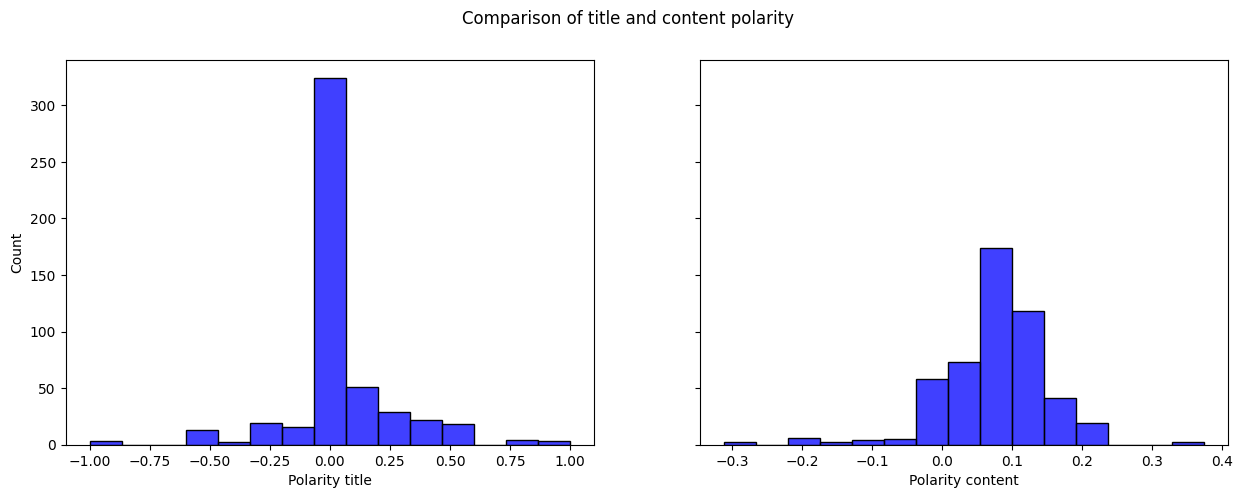

In [ ]:
# Convert Spark DataFrame to Pandas DataFrame
articles_with_sentiment_pandas = articles_with_sentiment.select("polarity_title", "polarity_content").toPandas()

# Set up Seaborn style and figure size
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
fig.suptitle('Comparison of title and content polarity')

# Create the scatter plot with Seaborn
sns.histplot(
    ax=axes[0],
    data=articles_with_sentiment_pandas,
    x="polarity_title",
    color="b",
    bins=15
).set(xlabel = "Polarity title")
sns.histplot(
    ax=axes[1],
    data=articles_with_sentiment_pandas,
    x="polarity_content",
    color="b",
    bins=15
).set(xlabel = "Polarity content")

plt.show()

## 1.3 Sentiment analysis using LLMs

In this section, we will explore the use of Large Language Models (LLMs) for text classification tasks. LLMs have revolutionized natural language processing by enabling more accurate and context-aware understanding of text data. This makes packages like TextBlob outdated for more complex tasks. We will utilize the pre-trained FinBERT model from Hugging Face's Transformers library to create embeddings for our news articles. These embeddings will then be used as features in a classification model to predict financing announcements. For sentiment analysis, we will use the Gemma3:4b model to generate sentiment scores for each article. 

**Note:** For the assignment, be sure to make use of LLMs to process the news articles, and if needed, try to limit the computational cost by using a smaller model or limiting the number of requests!


Other features that can be generated by LLMs include:
- Topic Modeling: Extracting underlying topics from a collection of documents to understand the main themes.
- Summarization: Generating concise summaries of longer texts to capture the main points.

### 1.3.1 FinBERT Embeddings

In [ ]:
#To install torch with cuda support, follow instructions at https://pytorch.org/get-started/locally/. This will ensure that the model runs on GPU if available.
import torch

from pyspark.ml.functions import array_to_vector
from transformers import AutoTokenizer, AutoModel

In [ ]:
# runs long 
# Load the tokenizer and model
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModel.from_pretrained("ProsusAI/finbert")
embed_dim = 768  # FinBERT embedding dimension

# Set model to evaluation mode
model.eval()

# Determine device: GPU is preferred if a CUDA-enabled GPU is available. To install torch with cuda support, follow instructions at https://pytorch.org/get-started/locally/
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False

In [ ]:
def get_embeddings(text):
    if text is None or text == "":
        return None
    
    # Tokenize the input text
    inputs = tokenizer(text, 
                     padding=True, 
                     truncation=True, 
                     max_length=512,
                     return_tensors="pt")
    
    # Move inputs to device
    inputs = {key: val.to(device) for key, val in inputs.items()}
    
    # Generate embeddings without gradient computation
    with torch.no_grad():
        outputs = model(**inputs)

    # Mean pooling - take attention mask into account for correct averaging so we don't include padding tokens
    attention_mask = inputs['attention_mask']
    token_embeddings = outputs.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    embeddings = torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)
    
    # Convert to numpy and then to list
    embedding_list = embeddings.cpu().numpy()[0].tolist()
    
    return embedding_list

# Register the function as a UDF
get_embeddings_udf = F.udf(get_embeddings, ArrayType(DoubleType()))

In [ ]:
# Apply the UDF to get FinBERT embeddings for the content column
articles_df_with_embeddings = articles_with_sentiment.withColumn("finbert_embeddings", get_embeddings_udf(F.col("content_raw")))

In [ ]:
# We need to convert the list of floats to Spark's Vector type, but first filter out observations without embeddings
articles_df_with_embeddings = articles_df_with_embeddings.filter(F.col("finbert_embeddings").isNotNull())
articles_df_with_embeddings = articles_df_with_embeddings.withColumn("finbert_embeddings", array_to_vector(F.col("finbert_embeddings")))
articles_df_with_embeddings.cache().show()

+----------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------+---------------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+--------------------+----------------+------------------+--------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+--------------------+-------------------+-------------------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+--------------------+------------------+--------------------+-----------------+--------------+--------------------+------------------+--------------------+---------------

### 1.3.2 Ollama sentiment analysis

1) First type in the terminal: ollama pull gemma3:4b
2) start ollama service in terminal: ollama serve 
3) In another terminal, verify: ollama list should provide a gemma 3:4b

In [ ]:
#4 after downloading and starting ollama, run this 
import requests
import ollama

def setup_and_test_ollama():
    print("=" * 60)
    print("SETTING UP OLLAMA")
    print("=" * 60)
    
    # Step 1: Check if Ollama is running
    try:
        response = requests.get('http://localhost:11434/api/tags', timeout=5)
        if response.status_code == 200:
            print("✅ Ollama service is running")
        else:
            print(f"❌ Ollama API error: {response.status_code}")
            return False
    except requests.exceptions.ConnectionError:
        print("❌ Ollama service not running. Run 'ollama serve' in terminal")
        return False
    
    # Step 2: Check available models
    try:
        response = requests.get('http://localhost:11434/api/tags')
        models = response.json().get('models', [])
        
        if not models:
            print("❌ No models found. Download one with: ollama pull gemma3:4b")
            return False
        
        print(f"✅ Found {len(models)} model(s):")
        for model in models:
            print(f"   - {model.get('name')}")
        
        # Step 3: Check if gemma3:4b is available
        model_names = [m.get('name') for m in models]
        if 'gemma3:4b' not in model_names:
            print("❌ gemma3:4b not found. Download it with: ollama pull gemma3:4b")
            
            # Try to use any available model
            available_model = model_names[0]
            print(f"⚠️  Using available model: {available_model} instead")
            MODEL_NAME = available_model
        else:
            print("✅ gemma3:4b is available!")
            MODEL_NAME = 'gemma3:4b'
        
        # Step 4: Test the model
        print("\n🧪 Testing model with simple query...")
        try:
            response = ollama.chat(
                model=MODEL_NAME,
                messages=[{'role': 'user', 'content': 'What is 2+2?'}],
                options={'temperature': 0.1}
            )
            print(f"✅ Model test successful!")
            print(f"   Response: {response['message']['content'].strip()}")
            return True
        except Exception as e:
            print(f"❌ Model test failed: {e}")
            return False
            
    except Exception as e:
        print(f"❌ Error checking models: {e}")
        return False

# Run the setup
setup_and_test_ollama()

SETTING UP OLLAMA
✅ Ollama service is running
✅ Found 1 model(s):
   - gemma3:4b
✅ gemma3:4b is available!

🧪 Testing model with simple query...
✅ Model test successful!
   Response: 2 + 2 = 4


True

In [ ]:
# pass the name (and configuration) of the model from the ollama website
MODEL_NAME = 'gemma3:4b'

try:
    import ollama
    
    # simple prompt to test general knowledge
    response = ollama.chat(model=MODEL_NAME, 
                           messages=[
                            {
                                'role': 'user',
                                'content': 'Explain what NLP is in one sentence.'
                            }
                        ])
    
    # print response
    print("Ollama is working! The model is running locally on your machine!")
    print('='*50)
    print(f"RESPONSE FROM {MODEL_NAME.upper()}:")
    print(response['message']['content'])
    
except Exception as e:
    print(f"Could not connect to Ollama: ")
    print("\nMake sure:")
    print("1. Ollama application is installed")
    print("2. Python package is installed (pip install ollama)")
    print(f"3. You've downloaded a model (e.g., 'ollama pull {MODEL_NAME}')")
    print("4. Ollama is running (check terminal: 'ollama serve')")

Ollama is working! The model is running locally on your machine!
RESPONSE FROM GEMMA3:4B:
Natural Language Processing (NLP) is a field of computer science that focuses on enabling computers to understand, interpret, and generate human language.


In [ ]:
# Function to get sentiment using ollama
def get_ollama_sentiment(text):
    try:
        import ollama
        
        prompt = f"""Provide the sentiment of the following text as a single numerical value between -1 and 1, 
        where -1 is very negative, 0 is neutral, and 1 is very positive, from an investment perspective. Only provide the numerical value, 
        I don't want any explanation or other text answer.\n\nText: '{text}'"""
        
        response = ollama.chat(model=MODEL_NAME, 
                               messages=[
                                {
                                    'role': 'user',
                                    'content': prompt
                                }
                            ])
        
        return (response['message']['content'].strip())
    except Exception as e:
        return None
    
# Register udf
get_ollama_sentiment_udf = F.udf(get_ollama_sentiment, StringType())

In [ ]:
# not really necessary if it works 
# Test the prompt first before applying to all articles
articles_df_with_embeddings_pandas = articles_df_with_embeddings.toPandas()
print(get_ollama_sentiment(articles_df_with_embeddings_pandas['content_raw'].iloc[0]))

0.85


In [ ]:
articles_df_with_embeddings.show(1000)

+----------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------+---------------+------------+----------+-----------+------------+-----------+----------+-------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+--------------------+----------------+------------------+--------------------+--------------------+--------------------+---------+--------------------+--------------------+-------+---------+--------------------+-------------------+-------------------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+--------------------+-------------------+--------------------+-----------------+--------------------+--------------------+-------------------+--------------------+----

In [ ]:
# Apply ollama sentiment analysis
articles_with_ollama_sentiment = articles_df_with_embeddings.withColumn("ollama_sentiment", get_ollama_sentiment_udf(F.col("content_raw")))

# --- MINIMAL FIX: REMOVE "Transcript:" PREFIX ---
# Simple regex replace that only affects rows starting with Transcript:
# Instead of just removing "Okay" prefix, set the entire value to 0 when it starts with "Okay"
articles_with_ollama_sentiment = articles_with_ollama_sentiment.withColumn(
    "ollama_sentiment",
    F.when(
        F.lower(F.col("ollama_sentiment")).startswith("okay"),
        F.lit(0).cast("double")
    ).otherwise(F.col("ollama_sentiment"))
)

articles_with_ollama_sentiment.show(1000)




+----------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------+---------------+------------+----------+-----------+------------+-----------+----------+-------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+--------------------+----------------+------------------+--------------------+--------------------+--------------------+---------+--------------------+--------------------+-------+---------+--------------------+-------------------+-------------------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+--------------------+-------------------+--------------------+-----------------+--------------------+--------------------+-------------------+--------------------+----

In [ ]:
# Aggregate features by biweekly period
basetable = articles_with_ollama_sentiment.groupBy("period_start", "period_end", "biweekly_period", "next_announcement") \
    .agg(
        F.count("text_features").alias("num_articles"),
        F.avg("num_words_title").alias("avg_num_words_title"),
        F.avg("num_words_content").alias("avg_num_words_content"),
        F.avg("polarity_title").alias("avg_polarity_title"),
        F.avg("polarity_content").alias("avg_polarity_content"),
        F.avg("subjectivity_title").alias("avg_subjectivity_title"),
        F.avg("subjectivity_content").alias("avg_subjectivity_content"),
        F.last("finbert_embeddings").alias("finbert_embeddings"), # we use last for simplicity here, 
        # because averaging Vector types in Spark isn't possible. You can however do this using custom functions
        F.avg("ollama_sentiment").alias("avg_ollama_sentiment")
    ) \
    .orderBy("period_start")

basetable.show()

+------------+----------+---------------+-----------------+------------+-------------------+---------------------+--------------------+--------------------+----------------------+------------------------+--------------------+--------------------+
|period_start|period_end|biweekly_period|next_announcement|num_articles|avg_num_words_title|avg_num_words_content|  avg_polarity_title|avg_polarity_content|avg_subjectivity_title|avg_subjectivity_content|  finbert_embeddings|avg_ollama_sentiment|
+------------+----------+---------------+-----------------+------------+-------------------+---------------------+--------------------+--------------------+----------------------+------------------------+--------------------+--------------------+
|  2024-05-21|2024-05-31|             P9|                0|          15|                7.0|    435.6666666666667|                 0.1|0.047855116419931246|   0.16666666666666666|     0.40509077410425465|[-0.0250109918415...|-0.09999999999999999|
|  2024-06-0

## 2. Modeling

In this section, we’ll train some basic predictive models to predict financing announcements. We’ll use the first 8 months of our dataset for training, reserving the final 3 months for model evaluation. By relying exclusively on lagged variables as predictors, we ensure that the model only uses historical information to make forward-looking predictions—mirroring the real-world constraint of forecasting based solely on past data.

When working with time series data, particularly in stock price analysis, it’s essential to maintain the temporal order of observations. Randomly splitting the data into training and testing sets can lead to information leakage, as future information may inadvertently influence the model during training. To prevent this, a time-based split should be used instead.

### 2.1 Time-based Split
A time-based split involves using the earlier portion of the dataset for training and reserving the later portion for testing. This approach mirrors a real-world scenario in which we predict future announcements based solely on historical data, ensuring that our model remains grounded in past information while evaluating its ability to forecast what comes next.

In [ ]:
# Use the first 2/3 of the data for training and the last 1/3 for testing
train_size = int(basetable.count() * 0.67)
train_df = basetable.limit(train_size)

# Use the remaining data for testing
test_df = basetable.subtract(train_df)

### 2.2. Check Missing Values

In [ ]:
# get all numeric columns
numeric_cols = [c for c, t in train_df.dtypes if isinstance(train_df.schema[c].dataType, NumericType)]

# count null values in each column
null_counts_train = train_df.select([F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c) for c in numeric_cols])
null_counts_train.show()

null_counts_test = test_df.select([F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c) for c in numeric_cols])
null_counts_test.show()

+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+
|next_announcement|num_articles|avg_num_words_title|avg_num_words_content|avg_polarity_title|avg_polarity_content|avg_subjectivity_title|avg_subjectivity_content|avg_ollama_sentiment|
+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+
|                0|           0|                  0|                    0|                 0|                   0|                     0|                       0|                   0|
+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+

+-----------------+------------+-------------------+---------------------+-----

### 2.3 Check Label Distribution in Train & Test set

In [ ]:
# check label distribution in train test
train_label_distr = train_df.groupBy('next_announcement').count()
train_label_distr.show()

# check label distribution in test test
test_label_distr = test_df.groupBy('next_announcement').count()
test_label_distr.show()

+-----------------+-----+
|next_announcement|count|
+-----------------+-----+
|                0|   49|
|                1|    1|
+-----------------+-----+

+-----------------+-----+
|next_announcement|count|
+-----------------+-----+
|                1|    3|
|                0|   23|
+-----------------+-----+



### 2.4 Scale Numeric Features

In [ ]:
exclude_columns = ["biweekly_period", "period_start", "period_end", "next_announcement"]
feature_columns = [col for col in train_df.columns if col not in exclude_columns]
VA = VectorAssembler(inputCols=feature_columns, outputCol="features", handleInvalid = "skip")

In [ ]:
# define the standardizer (standard normal)
SS = StandardScaler(inputCol="features", outputCol="featuresNorm", withMean=False, withStd=True)

### 2.5 Regularized Logistic Regression

In [ ]:

# define logistic regression model
LR = LogisticRegression(featuresCol="featuresNorm", labelCol="next_announcement", elasticNetParam=0.8, regParam=0.001)

# fit model on train
lr_pipeline = Pipeline(stages=[VA, SS, LR])

# model training
lr_model = lr_pipeline.fit(train_df)

In [ ]:
# predictions
lr_predictions = lr_model.transform(test_df)

In [ ]:
# show predictions
lr_predictions.select("period_start", "period_end", "next_announcement", "prediction").show()

+------------+----------+-----------------+----------+
|period_start|period_end|next_announcement|prediction|
+------------+----------+-----------------+----------+
|  2025-05-12|2025-05-12|                1|       0.0|
|  2025-05-14|2025-05-14|                0|       0.0|
|  2025-05-19|2025-05-30|                0|       0.0|
|  2025-05-20|2025-05-30|                0|       0.0|
|  2025-05-20|2025-05-30|                1|       0.0|
|  2025-05-26|2025-05-26|                0|       0.0|
|  2025-05-26|2025-05-30|                0|       0.0|
|  2025-06-02|2025-06-13|                0|       0.0|
|  2025-06-02|2025-06-13|                1|       0.0|
|  2025-06-16|2025-06-20|                0|       0.0|
|  2025-06-16|2025-06-27|                0|       0.0|
|  2025-06-30|2025-07-11|                0|       0.0|
|  2025-07-03|2025-07-04|                0|       0.0|
|  2025-07-04|2025-07-04|                0|       0.0|
|  2025-07-14|2025-07-25|                0|       0.0|
|  2025-07

In [ ]:
def calculate_classification_metrics(predictions, label_col, prediction_col):
    # calculate true positives, true negatives, false positives, false negatives
    tp = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 1)).count()
    tn = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 0)).count()
    fp = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 1)).count()
    fn = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 0)).count()

    # calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # calculate precision
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0  
    
    # calculate recall
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0.0  
    
    # calculate F1 measure
    f1_measure = 2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0.0  

    # print the metrics
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 measure: {f1_measure}")
    
    return accuracy, precision, recall, f1_measure

In [ ]:
# get metrics
lr_accuracy, lr_precision, lr_recall, lr_f1_measure = calculate_classification_metrics(lr_predictions, 'next_announcement', 'prediction')

Accuracy: 0.8846153846153846
Precision: 0
Recall: 0.0
F1 measure: 0.0


In [ ]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="next_announcement", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")

lr_AUC = evaluator.evaluate(lr_predictions)
print(f"AUC: {lr_AUC:.4f}")

AUC: 0.3406


### 2.6 Random forest

In [ ]:
# define random forest model
RF = RandomForestClassifier(featuresCol="featuresNorm", labelCol="next_announcement", numTrees=100)

# fit model on train
rf_pipeline = Pipeline(stages=[VA, SS, RF])

# Model training
rf_model = rf_pipeline.fit(train_df)

In [ ]:
# predictions
rf_predictions = rf_model.transform(test_df)

In [ ]:
# show predictions
rf_predictions.select("period_start", "period_end", "next_announcement", "prediction").show()

+------------+----------+-----------------+----------+
|period_start|period_end|next_announcement|prediction|
+------------+----------+-----------------+----------+
|  2025-05-12|2025-05-12|                1|       0.0|
|  2025-05-14|2025-05-14|                0|       0.0|
|  2025-05-19|2025-05-30|                0|       0.0|
|  2025-05-20|2025-05-30|                0|       0.0|
|  2025-05-20|2025-05-30|                1|       0.0|
|  2025-05-26|2025-05-26|                0|       0.0|
|  2025-05-26|2025-05-30|                0|       0.0|
|  2025-06-02|2025-06-13|                0|       0.0|
|  2025-06-02|2025-06-13|                1|       0.0|
|  2025-06-16|2025-06-20|                0|       0.0|
|  2025-06-16|2025-06-27|                0|       0.0|
|  2025-06-30|2025-07-11|                0|       0.0|
|  2025-07-03|2025-07-04|                0|       0.0|
|  2025-07-04|2025-07-04|                0|       0.0|
|  2025-07-14|2025-07-25|                0|       0.0|
|  2025-07

In [ ]:
# get metrics
rf_accuracy, rf_precision, rf_recall, rf_f1_measure = calculate_classification_metrics(rf_predictions, 'next_announcement', 'prediction')

Accuracy: 0.8846153846153846
Precision: 0
Recall: 0.0
F1 measure: 0.0


In [ ]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="next_announcement", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")

rf_AUC = evaluator.evaluate(rf_predictions)
print(f"AUC: {rf_AUC:.4f}")

AUC: 0.6087


In [ ]:
# check which algorithm is the best
print("LOGISTIC REGRESSION:")
print('  ACCURACY   : %g' % lr_accuracy)
print('  PRECISION  : %g' % lr_precision)
print('  RECALL     : %g' % lr_recall)
print('  AUC        : %g' % lr_AUC)
print('  F1         : %g' % lr_f1_measure)
print("------------------")
print("RANDOM FOREST:")
print('  ACCURACY   : %g' % rf_accuracy)
print('  PRECISION  : %g' % rf_precision)
print('  RECALL     : %g' % rf_recall)
print('  AUC        : %g' % rf_AUC)
print('  F1         : %g' % rf_f1_measure)

LOGISTIC REGRESSION:
  ACCURACY   : 0.884615
  PRECISION  : 0
  RECALL     : 0
  AUC        : 0.34058
  F1         : 0
------------------
RANDOM FOREST:
  ACCURACY   : 0.884615
  PRECISION  : 0
  RECALL     : 0
  AUC        : 0.608696
  F1         : 0


In [ ]:
# Stop the Spark session
spark.stop()
print("Spark session stopped successfully!")

Spark session stopped successfully!


# Next steps group assignment

**What you can do after this demo:**

    - Cleaning text
    - Extracting keywords
    - Creating NLP pipelines
    - Finetuning NLP pipelines
    - Using methods to aggregate Price history and News data
    - Experiment with different LLMs to generate features
    - ...

Get creative and get as much value out of the data as possible!